**EEG–Eye-Tracking Multimodal Research | Presented by: Reza Saadatyar (2026)**

**05 | Temporal Learning and Advanced Multimodal Fusion**

![Observed temporal-model Validation results and workflow](../../images/05_temporal_and_advanced_fusion.svg)

**Research question:** On the same participant-disjoint ZuCo 2.0 reading windows, does a compact gated EEG–gaze recurrent model improve on the strongest EEG-only or gaze-only GRU, and how does its Validation result compare with the classical baselines?

**Objective and executed scope:** Three predefined models, `gaze_gru`, `eeg_gru` and `gated_fusion_gru`, were trained using six consecutive two-second bins per 12-second window. Checkpoints were selected by Validation fixed-label Macro F1, Balanced Accuracy and then lower cross-entropy. No Test information was used for training, checkpoint selection or scoring.

**Dataset and recorded inputs:** ZuCo 2.0 (NEMAR `nm000279`, `v1.0.0`); `03_features.csv` and `03_temporal_sequences.npz` record **206 paired EEG/gaze windows**, with **six bins × four features** for each modality. Participant-disjoint roles remain **95 Train windows (three people)**, **31 Validation windows (one person)** and **80 reserved Test windows (two people)**.

**Recorded Validation outcome:** The EEG-only GRU led the three temporal candidates (Macro F1 **0.6890**, Balanced Accuracy **0.6932**), followed by gaze GRU (**0.3922**) and gated fusion GRU (**0.2619**). The gaze GRU predicted every Validation window as NR; the gated fusion GRU predicted every window as TSR. The strongest recorded classical model is still gaze logistic regression from Notebook 04 (Macro F1 **0.8862**) on these same 31 windows.

**Saved evidence:** `05_validation_metrics.csv`, `05_validation_predictions.csv` (93 model-window rows), `05_training_history.csv` (43 model-epoch rows), three `05_*.pt` checkpoints, `05_scaling.npz` and `05_learning_curves.png`. Validation metrics were independently recalculated from the saved predictions; they match the recorded values. The models were **not independently retrained** during this review.

**Scientific boundary:** These repeated Validation windows come from **one person**; the observed ranking cannot establish cross-person generalisation. NR/TSR labels capture source reading-task conditions, not comprehension, cognitive ability or a clinical outcome. The gating weights are not a physiological or causal explanation. **No Test predictions or metrics have been generated.**


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(
        ["git", "clone", "-q", repo_url, str(repo_path)], check=True
    )

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eeg_eye_tracking_fusion")

# ---------------------------- 2. Standard Library ----------------------------
import importlib.util
import random
import shutil
import sys

# ---------------------- 3. Colab Dependency Preparation ----------------------
if importlib.util.find_spec("mne") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install",
         "mne>=1.6,<2"],
        check=True,
    )

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 5. Machine Learning and Deep Learning -------------------
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# ------------------- 6. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style

# ----------------- 7. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from features import verify_temporal_feature_alignment
from models import (
    NEURAL_ORDER, CLASS_TO_INDEX, metrics, record_predictions,
    torch_network, predict_neural,
)

# ---------------------------- 8. Reproducibility -----------------------------
SEED = 17
random.seed(SEED)
np.random.seed(SEED)

# ------------------- 9. Output Directory and Setup Summary -------------------
work = root / "eeg_eye_tracking_fusion"
output_dir = work / "output"
output_dir.mkdir(parents=True, exist_ok=True)
raw_dir = Path("/content/zuco2_source_cache")
raw_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Project outputs:", output_dir)
print("Temporary source cache:", raw_dir)
print("Python:", sys.version.split()[0])
print("Free disk (GiB):", round(
    shutil.disk_usage("/content").free / 2**30, 2,
))


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Project outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eeg_eye_tracking_fusion/output
Temporary source cache: /content/zuco2_source_cache
Python: 3.13.18
Free disk (GiB): 106.27


**02. Verify Temporal Inputs and Fit Train-Only Scaling**

Load the exact Stage-03 six-bin EEG and gaze arrays, and verify their row order against the corresponding window-mean features. The existing NPZ stores some text identifiers as object arrays; read its **numeric arrays with `allow_pickle=False`** and take identities and split roles from the matching CSV. The Stage-02 registry is the authoritative source of eligibility and participant roles.

Fit missing-value replacement, means and standard deviations **only on Train bins**. Apply the same fitted transformations to both Train and Validation; do not use reserved Test data to estimate scaling parameters. Preserve the original six-bin order and the four-feature order within each modality.


In [3]:
# =============== 02. Load Sequences and Fit Train-Only Scaling ===============


torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
sequences = np.load(output_dir / '03_temporal_sequences.npz',
                    allow_pickle=False)
table = pd.read_csv(
    output_dir / '03_features.csv', dtype={'participant_id': str})
registry = pd.read_csv(
    output_dir / '02_window_registry.csv', dtype={'participant_id': str})
if table.empty or table.window_id.duplicated().any():
    raise ValueError('Stage-03 feature rows are missing or duplicated')
expected = registry.loc[
    registry.eligible, ['window_id', 'participant_id', 'task', 'split']]
if expected.window_id.duplicated().any():
    raise ValueError('Stage-02 eligible identities are duplicated')
if set(table.window_id) != set(expected.window_id):
    raise ValueError('Stage-03 window IDs differ from Stage-02 eligibility')
reference = table[['window_id', 'participant_id', 'task', 'split']].merge(
    expected, on='window_id', validate='one_to_one',
    suffixes=('_03', '_02'))
for field in ('participant_id', 'task', 'split'):
    if not reference[f'{field}_03'].eq(reference[f'{field}_02']).all():
        raise ValueError(f'Stage-03 {field} differs from Stage-02')
if not table.groupby('participant_id').split.nunique().eq(1).all():
    raise ValueError('A participant occurs in more than one partition')
if not table.task.isin(CLASS_TO_INDEX).all():
    raise ValueError('Unexpected task label in temporal features')
# Compare saved temporal values to the original per-window CSV means.
# This checks order without reading legacy object-encoded NPZ identifiers.
verify_temporal_feature_alignment(sequences, table)
print("Verified EEG/gaze temporal rows against Stage-03 feature means")
y = table.task.map(CLASS_TO_INDEX).to_numpy(dtype=int)
roles = table.split.to_numpy()
idx_train, idx_val = np.where(roles == 'train')[0], np.where(
    roles == 'validation')[0]
if min(len(idx_train), len(idx_val)) < 1:
    raise ValueError('Train or Validation is empty')
if (table.iloc[idx_train].task.nunique() != 2 or
        table.iloc[idx_val].task.nunique() != 2):
    raise ValueError('NR and TSR must occur in Train and Validation')
if not np.isfinite(y).all():
    raise ValueError('Invalid task labels')

def fit_scaler(original, training_rows):
    train = original[training_rows].reshape(-1, original.shape[-1])
    med = np.nanmedian(train, axis=0)
    med = np.where(np.isfinite(med), med, 0.)
    filled = np.where(np.isfinite(train), train, med)
    mean = filled.mean(axis=0)
    std = filled.std(axis=0)
    return med.astype('float32'), mean.astype('float32'), np.maximum(
        std, 1e-6).astype('float32')

def transform(original, median, mean, std):
    filled = np.where(np.isfinite(original), original, median)
    return ((filled - mean) / std).astype('float32')

eeg_med, eeg_mean, eeg_std = fit_scaler(sequences['eeg'], idx_train)
gaze_med, gaze_mean, gaze_std = fit_scaler(sequences['gaze'], idx_train)
eeg = transform(sequences['eeg'], eeg_med, eeg_mean, eeg_std)
gaze = transform(sequences['gaze'], gaze_med, gaze_mean, gaze_std)
np.savez_compressed(output_dir / '05_scaling.npz',
                    eeg_median=eeg_med, eeg_mean=eeg_mean,
                    eeg_std=eeg_std, gaze_median=gaze_med,
                    gaze_mean=gaze_mean, gaze_std=gaze_std)
print('Device:', device, 'Train windows:', len(idx_train),
      'Validation windows:', len(idx_val))


Verified EEG/gaze temporal rows against Stage-03 feature means
Device: cpu Train windows: 95 Validation windows: 31


**03. Define Compact Architectures and Fixed Training Settings**

The three prespecified architectures use a hidden width of 16 and the same Train/Validation examples: gaze-only GRU, EEG-only GRU, and a gated fusion GRU combining learned embeddings of both modalities before recurrent modelling.

Use AdamW with learning rate `1e-3`, weight decay `1e-3`, batch size 64, up to 15 epochs and early-stopping patience of four. Dropout is 0.2 in each network head. These are fixed development settings, not a Validation hyperparameter sweep.

The gates blend modality-specific representations. Their values are not evidence that a given sensory modality caused a particular classification.


In [4]:
# ======= 03. Define Compact Architectures and Fixed Training Settings ========

HIDDEN = 16
EPOCHS = 15
PATIENCE = 4
BATCH_SIZE = 64
LR = 1e-3
WEIGHT_DECAY = 1e-3
train_set = TensorDataset(
    torch.from_numpy(eeg[idx_train]),
    torch.from_numpy(gaze[idx_train]),
    torch.from_numpy(y[idx_train]).long())
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE,
                          shuffle=True, generator=generator)
print('Six-step sequence shape:', eeg.shape,
      'Candidate models:', NEURAL_ORDER)


Six-step sequence shape: (206, 6, 4) Candidate models: ('gaze_gru', 'eeg_gru', 'gated_fusion_gru')


**04. Train EEG-Only, Gaze-Only and Gated Fusion GRUs**

Fit each model on the 95 Train windows only. The recorded Validation windows determine its best checkpoint and early stopping, using fixed-label Macro F1, then Balanced Accuracy, then lower Validation cross-entropy.

The three candidates use the same two original feature arrays and label order (NR, TSR), although each single-modality GRU consumes only its own modality in the forward pass. This stage does not select the final study model or use Test scores.


In [5]:
# ============ 04. Train EEG-Only, Gaze-Only and Gated Fusion GRUs ============

histories, validation_rows, prediction_frames = [], [], []
fitted = {}
for name in NEURAL_ORDER:
    model = torch_network(name, eeg.shape[-1], gaze.shape[-1],
                          hidden=HIDDEN).to(device)
    optimiser = torch.optim.AdamW(
        model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    criterion = nn.CrossEntropyLoss()
    best_key, best_weights, best_epoch = None, None, None
    stale = 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for a, b, truth in train_loader:
            a, b, truth = a.to(device), b.to(device), truth.to(device)
            optimiser.zero_grad()
            loss = criterion(model(a, b), truth)
            loss.backward()
            optimiser.step()
            losses.append(float(loss.detach().cpu()))
        proba = predict_neural(model, eeg[idx_val], gaze[idx_val],
                               device=device)
        scores = metrics(y[idx_val], proba.argmax(axis=1))
        val_loss = float(-np.log(np.clip(
            proba[np.arange(len(idx_val)), y[idx_val]], 1e-8, 1
        )).mean())
        key = (scores['macro_f1'], scores['balanced_accuracy'],
               -val_loss)
        histories.append({'model': name, 'epoch': epoch,
                          'train_loss': float(np.mean(losses)),
                          'validation_loss': val_loss, **scores})
        if best_key is None or key > best_key:
            best_key = key
            best_epoch = epoch
            best_weights = {k: v.detach().cpu().clone()
                            for k, v in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
        if stale >= PATIENCE:
            break
    model.load_state_dict(best_weights)
    fitted[name] = model.cpu()
    result = predict_neural(model, eeg[idx_val], gaze[idx_val])
    scores = metrics(y[idx_val], result.argmax(axis=1))
    validation_rows.append({
        'model': name, 'partition': 'validation',
        'n_windows': len(idx_val),
        'n_people': table.iloc[idx_val].participant_id.nunique(),
        'parameters': sum(p.numel() for p in model.parameters()),
        'best_epoch': best_epoch, **scores})
    prediction_frames.append(record_predictions(
        table.iloc[idx_val], name, result))
    torch.save({'state_dict': best_weights, 'model': name,
                'hidden': HIDDEN, 'eeg_features': eeg.shape[-1],
                'gaze_features': gaze.shape[-1],
                'best_epoch': best_epoch},
               output_dir / f'05_{name}.pt')
    print(name, 'best epoch', best_epoch,
          'Validation F1', round(scores['macro_f1'], 4))


gaze_gru best epoch 15 Validation F1 0.3922
eeg_gru best epoch 9 Validation F1 0.689
gated_fusion_gru best epoch 15 Validation F1 0.2619


**05. Recorded Learning Curves and Validation Ranking**

Stage 05 saved **43 model-epoch records**: gaze GRU ran 15 epochs, EEG GRU ran 13 (with its best checkpoint at epoch 9), and gated fusion GRU ran 15. Early stopping and checkpoint selection used the same held-out Validation participant; training loss reduction alone was not treated as evidence of generalisation.

| Temporal candidate | Best epoch | Parameters | Validation Accuracy | Macro F1 | Balanced Accuracy |
| --- | ---: | ---: | ---: | ---: | ---: |
| EEG GRU | 9 | 1,090 | **0.7097** | **0.6890** | **0.6932** |
| Gaze GRU | 15 | 1,090 | 0.6452 | 0.3922 | 0.5000 |
| Gated fusion GRU | 15 | 2,354 | 0.3548 | 0.2619 | 0.5000 |

Each score is based on **31 Validation windows (20 NR, 11 TSR) belonging to one independent person**. The EEG GRU identified **15/20 NR** and **7/11 TSR** correctly. The gaze GRU classified all 31 as NR; the gated GRU classified all as TSR. These class-specific findings explain their low Macro F1 despite non-zero Accuracy.


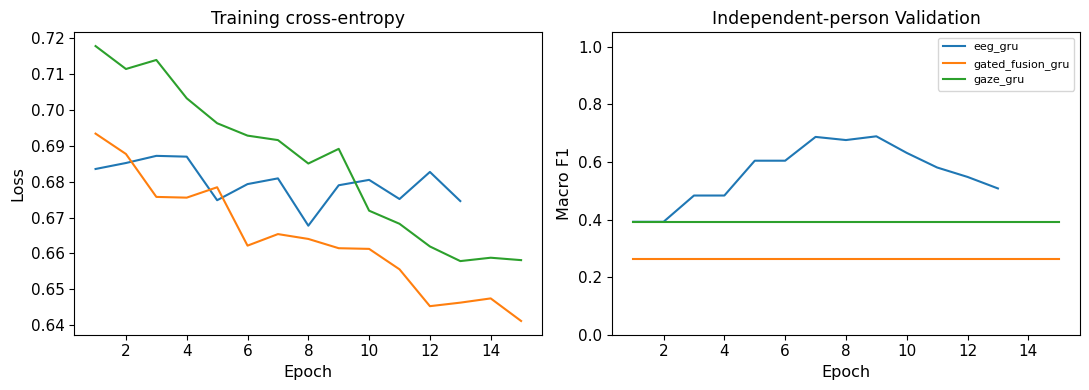

,model,partition,n_windows,n_people,parameters,best_epoch,accuracy,macro_f1,balanced_accuracy
1,eeg_gru,validation,31,1,1090,9,0.709677,0.688963,0.693182
0,gaze_gru,validation,31,1,1090,15,0.645161,0.392157,0.500000
2,gated_fusion_gru,validation,31,1,2354,15,0.354839,0.261905,0.500000


In [6]:
# ============= 05. Review Learning Curves and Validation Ranking =============

history = pd.DataFrame(histories)
neural_metrics = pd.DataFrame(validation_rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, frame in history.groupby('model'):
    axes[0].plot(frame.epoch, frame.train_loss, label=name)
    axes[1].plot(frame.epoch, frame.macro_f1, label=name)
axes[0].set(title='Training cross-entropy', xlabel='Epoch',
            ylabel='Loss')
axes[1].set(title='Independent-person Validation',
            xlabel='Epoch', ylabel='Macro F1', ylim=(0, 1.05))
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(output_dir / '05_learning_curves.png', dpi=170)
plt.show()
display(neural_metrics.sort_values('macro_f1', ascending=False))


**06. Recorded Validation Predictions and Saved Evidence**

The executed `05_validation_predictions.csv` contains **93 rows** (three models × 31 original Validation windows). Every model covers the same `window_id` set and the same held-out person (`sub-YDR`), with consistent source labels, fixed NR/TSR indices and finite, normalised class probabilities.

Accuracy, fixed-label Macro F1 and Balanced Accuracy were recalculated from the saved predictions and match all three rows in `05_validation_metrics.csv`. The three checkpoints, Train-fitted scaling parameters, 43-row epoch history and learning-curve plot are committed alongside these tables. These checks verify the recorded evidence, **not** a fresh training execution or model-state reconstruction.

The 80 Test windows (two other people) were **not scored**. Nothing from the Test partition should influence the selection in Notebook 06.


In [7]:
# ============ 06. Verify and Save Stage-05 Validation Predictions ============

pred = pd.concat(prediction_frames, ignore_index=True)
expected_ids = set(table.iloc[idx_val].window_id)
if set(pred.model) != set(NEURAL_ORDER):
    raise ValueError('Missing or unexpected temporal candidate')
for name, piece in pred.groupby('model'):
    if (len(piece) != len(idx_val) or
            piece.window_id.duplicated().any() or
            set(piece.window_id) != expected_ids):
        raise ValueError(f'Validation identity mismatch: {name}')
    aligned = piece.set_index('window_id').loc[
        table.iloc[idx_val].window_id].reset_index()
    source = table.iloc[idx_val].reset_index(drop=True)
    for column in ('participant_id', 'task', 'split'):
        if not aligned[column].astype(str).eq(
                source[column].astype(str)).all():
            raise ValueError(f'Validation {column} mismatch: {name}')
    if not np.array_equal(
            aligned.target_index.to_numpy(),
            y[idx_val]):
        raise ValueError(f'Target index mismatch: {name}')
    values = aligned[['p_nr', 'p_tsr']].to_numpy(dtype=float)
    if (not np.isfinite(values).all() or
            (values < 0).any() or (values > 1).any() or
            not np.allclose(values.sum(axis=1), 1., atol=1e-5)):
        raise ValueError(f'Invalid Validation probabilities: {name}')
pred.to_csv(output_dir / '05_validation_predictions.csv',
            index=False)
neural_metrics.to_csv(output_dir / '05_validation_metrics.csv',
                      index=False)
history.to_csv(output_dir / '05_training_history.csv', index=False)
print('Neural Validation rows:', len(pred))


Neural Validation rows: 93


**07. Interpretation and Next Dependency**

**Observed temporal comparison:** EEG GRU achieved the highest temporal-model Validation Macro F1 (**0.6890**). Gaze GRU reached **0.3922** and gated EEG–gaze GRU **0.2619**. Thus gated fusion did **not** improve on either temporal unimodal model in these recorded Validation windows.

**Across classical and temporal candidates:** Gaze logistic regression from Notebook 04 remains the highest recorded Validation candidate at **0.8862** Macro F1, exceeding the best temporal model by approximately **0.1972**. Both comparisons use the same **31 windows from a single held-out participant**. The observations do not establish general architectural superiority, consistent fusion harm, an explanation of neural processing or a real-world cognitive outcome. Source task/stimulus differences, ocular activity in EEG, limited independent participant support and metadata-derived alignment remain important uncertainties.

**Next:** [Notebook 06](06_robustness_and_final_evaluation.ipynb) reconciles **seven classical and three temporal** Validation candidates, saves the prespecified Validation-selected model and performs a **Validation-only feature-masking sensitivity analysis**. Its initial `RUN_FINAL_TEST=False` mode must remain in place; **no held-out Test scoring** is authorised for this development run.


In [8]:
# ================== 07. Interpretation and Next Dependency ===================

print('Next: 06_robustness_and_final_evaluation.ipynb')
download_outputs_from_colab("eeg_eye_tracking_fusion/output", "05")


Next: 06_robustness_and_final_evaluation.ipynb
------------------------------------------------------------------------
Notebook 05
Files packaged: 8
  + 05_eeg_gru.pt
  + 05_gated_fusion_gru.pt
  + 05_gaze_gru.pt
  + 05_learning_curves.png
  + 05_scaling.npz
  + 05_training_history.csv
  + 05_validation_metrics.csv
  + 05_validation_predictions.csv
Download ZIP from Colab Contents: /content/eeg_eye_tracking_fusion_Notebook_05_Outputs.zip
